In [69]:
import json
from importlib import resources
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

import pptoolbox
from pptoolbox.embeddings.lsm.multimodal import MultiModalMAE
from pptoolbox.interpolate.target_wavelengths import WAVELENGTHS_QMINI, WAVELENGTHS_QNEO
from pptoolbox.match import SpectraMatcher
from pptoolbox.metrics import match_similarity
from pptoolbox.platform.module_preprocessor_defaults import NETWORK_PREPROCESSOR_DEFAULTS
from pptoolbox.platform.preprocessor_constructor import construct_preprocessor_from_params

In [70]:
def transform_to_lsm_embeddings(input_df: pd.DataFrame) -> pd.DataFrame:
    """Embed non-coffee spectra with the Multi-Modal LSM model."""
    lsm_dir = resources.files(pptoolbox)
    preprocessor = construct_preprocessor_from_params(NETWORK_PREPROCESSOR_DEFAULTS)

    with lsm_dir.joinpath('embeddings/lsm/configs/configs.json').open() as config_file:
        configs = json.load(config_file)

    network = MultiModalMAE.from_configs(configs['network'])
    weights = torch.load(
        lsm_dir.joinpath('embeddings/models/LSM.pt'),
        weights_only=True,
        map_location=torch.device('cpu'),
    )
    network.load_state_dict(weights)
    network.eval()

    X_vis = torch.tensor(
        preprocessor.transform(input_df[WAVELENGTHS_QMINI]), dtype=torch.float32
    )
    with torch.no_grad():
        if input_df.shape[1] == len(WAVELENGTHS_QMINI):
            embeddings, _ = network.encode(X_vis)
        else:
            X_ex = torch.tensor(
                preprocessor.transform(input_df[WAVELENGTHS_QNEO]), dtype=torch.float32
            )
            embeddings, _ = network.encode(X_vis, X_ex=X_ex)

    return pd.DataFrame(embeddings[:, 0, :].numpy(), index=input_df.index)

In [71]:
def match_all_spectra(spectra: pd.DataFrame) -> pd.DataFrame:
    """Match every spectrum against every other using the non-coffee LSM path."""
    if spectra.shape[0] < 2:
        raise ValueError('At least two spectra are required.')

    embeddings = transform_to_lsm_embeddings(spectra)
    matcher = SpectraMatcher(match_similarity, center=False, aggregate=False)
    scores = matcher.match_spectra(candidates=embeddings, targets=embeddings)

    results = pd.DataFrame(scores, index=spectra.index, columns=spectra.index)
    # np.fill_diagonal(results.values, np.nan)
    return results

In [72]:
def sort_by_lot_name(
    X: pd.DataFrame,
    y: pd.DataFrame,
    *aligned_frames: pd.DataFrame,
    label_column: str = 'lot_name',
) -> tuple[pd.DataFrame, ...]:
    """Sort X, y, and any aligned frames by y's lot name."""
    frames = (X, y, *aligned_frames)
    if label_column not in y:
        raise KeyError(f'{label_column!r} is not a column in y.')
    if any(len(frame) != len(y) for frame in frames):
        raise ValueError('X, y, and aligned frames must have the same number of rows.')

    # Stable sorting preserves the original order of the five replicates.
    order = np.argsort(y[label_column].to_numpy(), kind='stable')
    return tuple(frame.iloc[order].copy() for frame in frames)

In [73]:
full_dir = Path('../data/processed/v1/full')

X_full = pd.read_csv(full_dir / 'input.csv', index_col=0)
# The LSM wavelength constants are floats; CSV headers are read as strings.
X_full.columns = X_full.columns.astype(float)
y_full = pd.read_csv(full_dir / 'label.csv', index_col=0)
meta_full = pd.read_csv(full_dir / 'meta.csv', index_col=0)

X_full, y_full, meta_full = sort_by_lot_name(X_full, y_full, meta_full)

X_full.shape

(85, 391)

In [74]:
mask_300 = y_full['volume'] == "300uL"

X_300 = X_full[mask_300]
y_300 = y_full[mask_300]
meta_300 = meta_full[mask_300]

X_800 = X_full[~mask_300]
y_800 = y_full[~mask_300]
meta_800 = meta_full[~mask_300]

In [75]:
def plot_replicate_match_heatmap(
    matches: pd.DataFrame,
    labels: pd.DataFrame,
    label_column: str = 'lot_name',
    group_size: int = 5,
):
    """Plot a match matrix with boxed, labelled replicate groups."""
    if len(matches) != len(labels) or len(matches) % group_size:
        raise ValueError('Matches and labels must have equal lengths divisible by group_size.')

    group_names = labels[label_column].iloc[::group_size].to_numpy()
    if not all(
        block[label_column].nunique() == 1
        for _, block in labels.groupby(np.arange(len(labels)) // group_size, sort=False)
    ):
        raise ValueError(f'Each {group_size}-row group must share one {label_column}.')

    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(matches, cmap='Blues',cbar_kws={'label': 'LSM similarity score'}, ax=ax)

    boundaries = np.arange(0, len(matches) + 1, group_size)
    for boundary in boundaries:
        ax.axhline(boundary, color='white', linewidth=1.5)
        ax.axvline(boundary, color='white', linewidth=1.5)

    centres = boundaries[:-1] + group_size / 2
    ax.set_xticks(centres, group_names, rotation=45, ha='right')
    ax.set_yticks(centres, group_names, rotation=0)
    ax.set_xlabel('Target lot')
    ax.set_ylabel('Candidate lot')
    fig.tight_layout()
    return ax

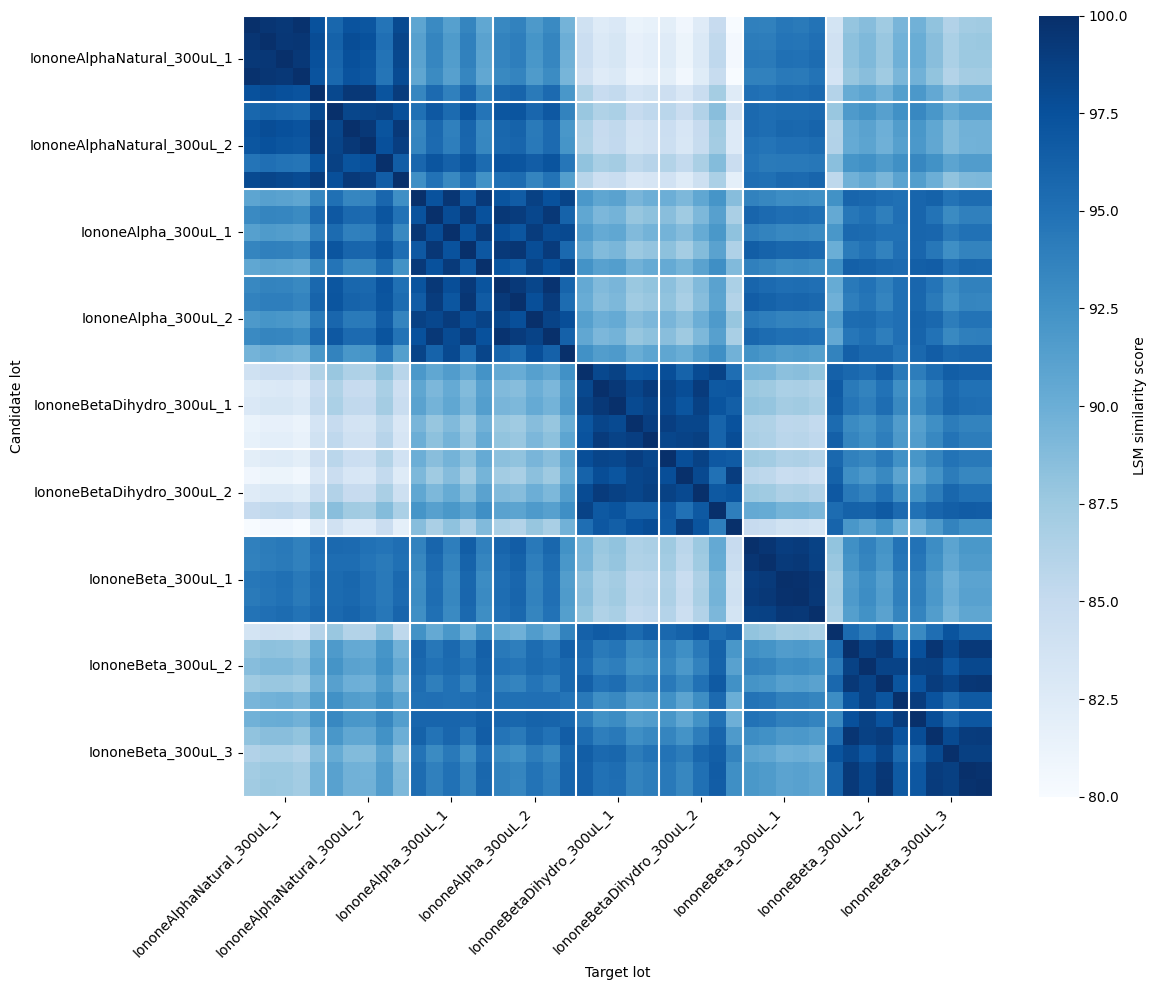

In [76]:
vol300_matches = match_all_spectra(X_300)
plot_replicate_match_heatmap(vol300_matches, y_300)
plt.show()

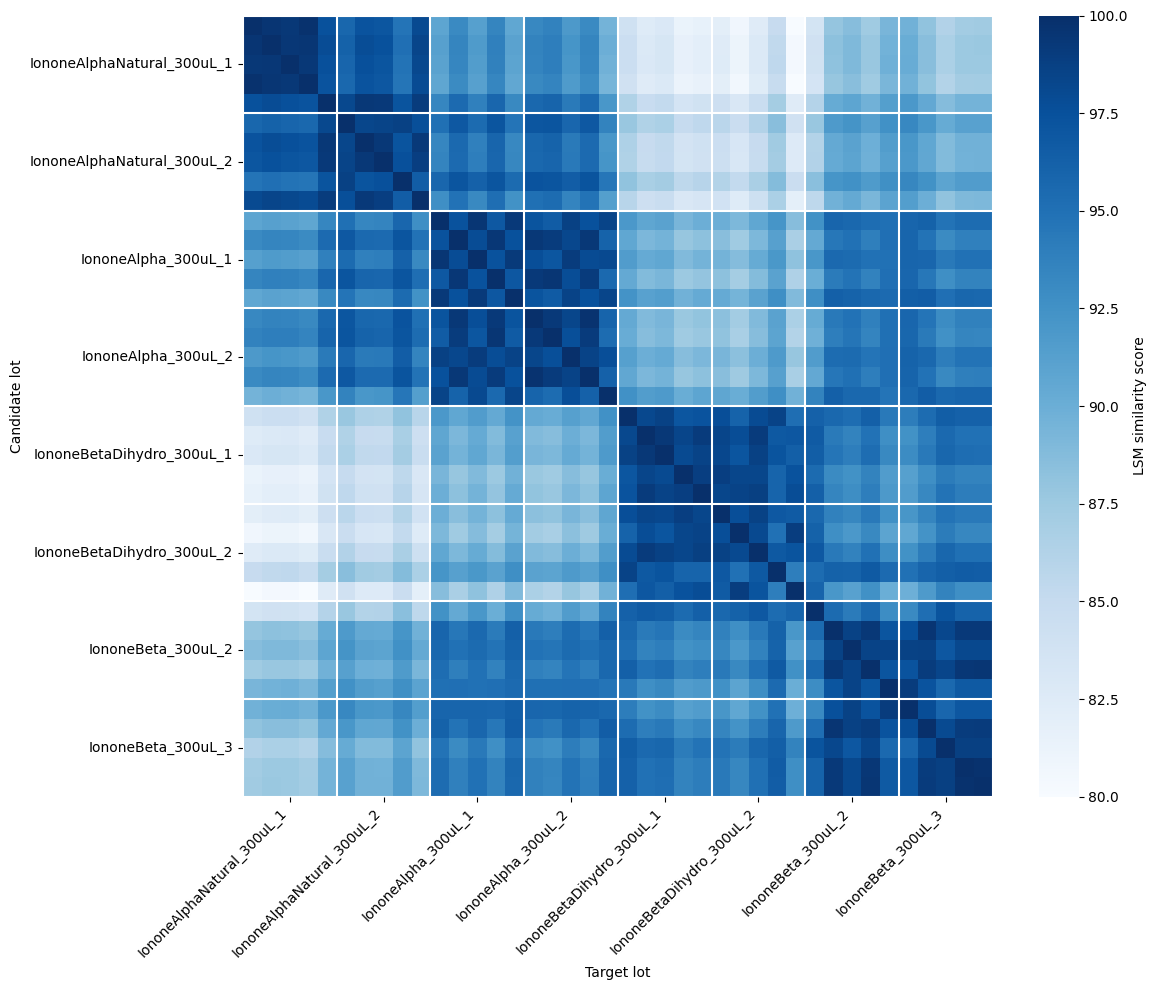

In [80]:
mask = y_300['lot_name']=='IononeBeta_300uL_1'
X_300_masked = X_300[~mask]
y_300_masked = y_300[~mask]
meta_300_masked = meta_300[~mask]


vol300_matches = match_all_spectra(X_300_masked)
plot_replicate_match_heatmap(vol300_matches, y_300_masked)
plt.show()

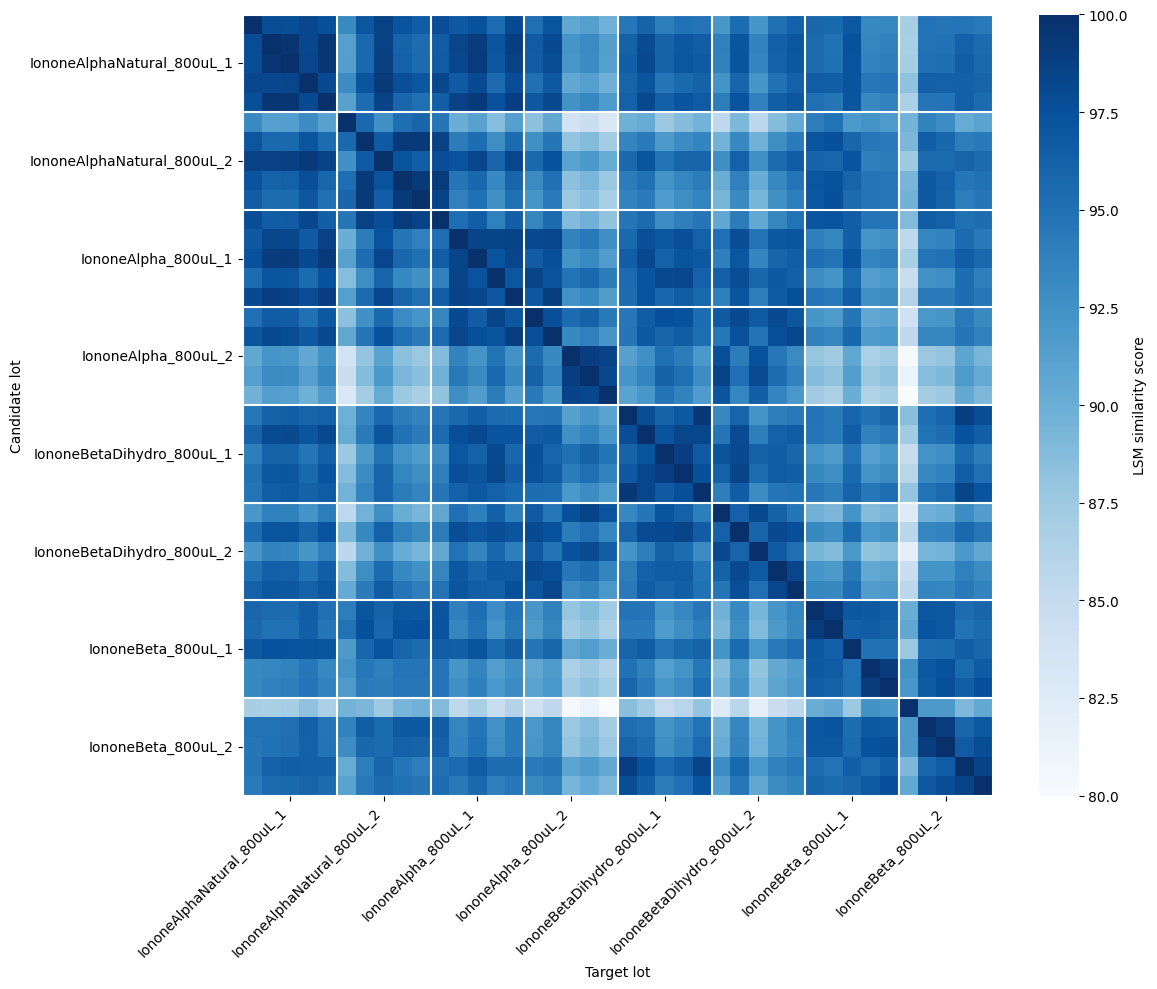

In [77]:
vol800_matches = match_all_spectra(X_800)
plot_replicate_match_heatmap(vol800_matches, y_800)
plt.show()